# Figures: cost, conditioning and reproducibility

Generates the figures of the page *Theory → Numerical limits and conditioning*:

1. **Cost** (`numerical_limits_cost.svg`): time to fill $Z$ with the three assemblers of the solver (per-pair loop on CPU, batched on CPU, batched on GPU) and to solve $ZI = V$, against the number of RWG edges $N$, on square plates meshed without gmsh.
2. **Conditioning** (`numerical_limits_conditioning.svg`): condition number of $Z$ against $kh$, by lowering the frequency and by refining the mesh; and how low in frequency a small loop keeps a correct input impedance, with `fill_mode="full_sym"` (default) and `"mirror"`.
3. **Reproducibility of gmsh meshes** with one thread and with several (printed, no figure).

Everything runs with the current solver; nothing is written to `data/` (temporary folders only).

In [1]:
%matplotlib inline
import datetime
import json
import os
import platform
import tempfile
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from fontTools.ttLib import TTFont
from matplotlib import font_manager

from solver.optim.geometries.planar import tensor_grid_mesh
from solver.utils.impmet import impedance_matrix_z, impedance_matrix_z_sweep_gpu
from solver.utils.compute_backend import GPU_AVAILABLE, describe_backend

OUT_DIR = Path("../source/figures/generated")
OUT_DIR.mkdir(parents=True, exist_ok=True)

BLUE, AMBER, INK, GREY = "#2563a6", "#e28a36", "#142b45", "#9aa5b1"
font_cache = Path(tempfile.gettempdir()) / "antenna_solver_docs_fonts"
font_cache.mkdir(exist_ok=True)
for variant in ("400-normal", "400-italic", "700-normal"):
    ttf = font_cache / f"iosevka-{variant}.ttf"
    if not ttf.exists():
        font = TTFont(Path("../source/_static/fonts/iosevka") / f"iosevka-latin-{variant}.woff2")
        font.flavor = None
        font.save(ttf)
    font_manager.fontManager.addfont(str(ttf))
plt.rcParams.update({
    "font.family": "Iosevka", "font.size": 11, "svg.fonttype": "path",
    "mathtext.fontset": "custom", "mathtext.rm": "Iosevka",
    "mathtext.it": "Iosevka:italic", "mathtext.bf": "Iosevka:bold",
})

# Constants of rwg3.calculate_z_matrice
EPS0, MU0 = 8.854e-12, 1.257e-6
C0 = 1 / np.sqrt(EPS0 * MU0)

def plate(side, n):
    """Square plate side x side in z = 0, n x n cells (2 triangles each), no gmsh."""
    x = np.linspace(-side / 2, side / 2, n + 1)
    return tensor_grid_mesh(x, x.copy())

def z_cpu_loop(mesh, f, fill_mode=None):
    w = 2 * np.pi * f
    return impedance_matrix_z(mesh.edges, mesh.triangles, mesh.points, 1j * w / C0, w, MU0, EPS0, fill_mode=fill_mode)

def z_batched(mesh, freqs, use_gpu, fill_mode=None):
    return impedance_matrix_z_sweep_gpu(mesh.edges, mesh.triangles, mesh.points, np.atleast_1d(freqs), MU0, EPS0,
                                        use_gpu=use_gpu, fill_mode=fill_mode)

machine = {"cpu": platform.processor(), "cpu_count": os.cpu_count(), "backend": describe_backend()}
print(machine)

{'cpu': 'Intel64 Family 6 Model 154 Stepping 3, GenuineIntel', 'cpu_count': 16, 'backend': 'GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1)'}


In [2]:
# 1. Cost against N. Plate of 0.15 m at 1 GHz (lambda/2), refined.
# Each assembler is timed while its predicted time stays under BUDGET_S. The prediction
# extrapolates from the last two sizes with the measured exponent (2 until two sizes exist);
# a skipped size is recorded as NaN, never extrapolated into the results.
F_COST, SIDE_COST = 1e9, 0.15
N_CELLS = [6, 9, 13, 18, 26, 36]
BUDGET_S = 300.0
PROGRESS = Path(tempfile.gettempdir()) / "mom_docs_numerical_limits_progress.log"
PROGRESS.write_text("", encoding="utf-8")

def log(msg):
    print(msg, flush=True)
    with PROGRESS.open("a", encoding="utf-8") as fh:
        fh.write(msg + "\n")

def timed(fn, *args, **kw):
    t0 = time.perf_counter(); out = fn(*args, **kw); return out, time.perf_counter() - t0

def predicted(history, N):
    if len(history) >= 2:
        (n1, t1), (n2, t2) = history[-2:]
        p = max(1.0, np.log(t2 / t1) / np.log(n2 / n1))
    else:
        p = 2.0
    n0, t0 = history[-1]
    return t0 * (N / n0) ** p

_ = z_batched(plate(SIDE_COST, 4), F_COST, use_gpu=GPU_AVAILABLE)   # warm-up: CUDA context and kernels

methods = {
    "t_gpu": (lambda m: z_batched(m, F_COST, use_gpu=True)[0]) if GPU_AVAILABLE else None,
    "t_batched_cpu": lambda m: z_batched(m, F_COST, use_gpu=False)[0],
    "t_loop_cpu": lambda m: z_cpu_loop(m, F_COST),
}
history = {k: [] for k in methods}
cost = []
for n in N_CELLS:
    mesh = plate(SIDE_COST, n)
    N = mesh.n_edges
    row = dict(n_cells=n, N=N, h_over_lambda=SIDE_COST / n / (C0 / F_COST), z_bytes=16 * N * N)
    Z = {}
    for key, fn in methods.items():
        if fn is None:
            row[key] = np.nan; continue
        if history[key] and predicted(history[key], N) > BUDGET_S:
            row[key] = np.nan
            log(f"N = {N}: {key} skipped (predicted {predicted(history[key], N):.0f} s > {BUDGET_S:.0f} s)")
            continue
        Z[key], row[key] = timed(fn, mesh)
        history[key].append((N, row[key]))
        log(f"N = {N}: {key} = {row[key]:.2f} s")
    if not Z:
        log(f"N = {N}: every assembler over budget, stop.")
        break
    ref = Z.get("t_batched_cpu")
    for key in ("t_gpu", "t_loop_cpu"):
        if ref is not None and key in Z:
            row[f"max_rel_diff_{key}_vs_batched_cpu"] = float(np.max(np.abs(Z[key] - ref)) / np.max(np.abs(ref)))
    Zs = next(iter(Z.values()))
    V = np.zeros(N, complex); V[N // 2] = 1.0
    _, row["t_solve"] = timed(np.linalg.solve, Zs, V)
    log(f"N = {N}: solve = {row['t_solve']:.3f} s; " +
        ", ".join(f"{k} = {v:.1e}" for k, v in row.items() if k.startswith("max_rel_diff")))
    cost.append(row)
    del Z, Zs

N = 96: t_gpu = 2.79 s


N = 96: t_batched_cpu = 6.40 s


N = 96: t_loop_cpu = 6.23 s


N = 96: solve = 0.000 s; max_rel_diff_t_gpu_vs_batched_cpu = 1.1e-16, max_rel_diff_t_loop_cpu_vs_batched_cpu = 8.5e-16


N = 225: t_gpu = 5.34 s


N = 225: t_batched_cpu = 17.28 s


... (14 outputs left out)

N = 3816: t_gpu = 219.72 s


N = 3816: t_batched_cpu skipped (predicted 786 s > 300 s)


N = 3816: t_loop_cpu skipped (predicted 2884 s > 300 s)


N = 3816: solve = 2.635 s; 


In [3]:
# Where does the fill time go? Profile one batched GPU assembly (or CPU if no GPU), N = 481.
import cProfile
import pstats
import io

mesh_prof = plate(SIDE_COST, 13)
prof = cProfile.Profile()
prof.enable()
z_batched(mesh_prof, F_COST, use_gpu=GPU_AVAILABLE)
prof.disable()
stream = io.StringIO()
stats = pstats.Stats(prof, stream=stream)
stats.sort_stats("cumulative").print_stats(25)
print(stream.getvalue()[:7000])
stream = io.StringIO()
pstats.Stats(prof, stream=stream).sort_stats("tottime").print_stats(15)
print(stream.getvalue()[:5000])
profile_total = stats.total_tt
profile_tottime = sorted(((k[2], k[0].split(os.sep)[-1], v[2]) for k, v in stats.stats.items()), key=lambda r: -r[2])[:10]
log(f"profile N = {mesh_prof.n_edges}: total {profile_total:.2f} s; own time: " +
    "; ".join(f"{name} ({mod}) {t:.2f} s" for name, mod, t in profile_tottime))

         11564191 function calls (11564190 primitive calls) in 18.220 seconds

   Ordered by: cumulative time
   List reduced from 243 to 25 due to restriction <25>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
      3/2    0.000    0.000   18.220    9.110 c:\Users\foyendou\miniconda3\envs\antenna_solver\Lib\site-packages\IPython\core\interactiveshell.py:3634(run_code)
        2    0.000    0.000   18.220    9.110 {built-in method builtins.exec}
        1    0.000    0.000   18.219   18.219 C:\Users\foyendou\AppData\Local\Temp\ipykernel_22584\1832453926.py:1(<module>)
        1    0.019    0.019   18.219   18.219 C:\Users\foyendou\AppData\Local\Temp\ipykernel_22584\3099982186.py:51(z_batched)
        4    1.117    0.279   13.510    3.378 c:\Users\foyendou\miniconda3\envs\antenna_solver\Lib\asyncio\base_events.py:1922(_run_once)
    33432    1.864    0.000    9.018    0.000 d:\phd_fahdilou_leat\projets_github\antenna_solver_mom\solver\utils\quadrature\duffy.py

In [4]:
# 2. Conditioning of Z against kh (h = cell side).
#    (a) one mesh, the frequency lowered;  (b) one frequency, the mesh refined.
SIDE_COND = 0.10
mesh_cond = plate(SIDE_COND, 10)
h_cond = SIDE_COND / 10
FREQS_COND = np.logspace(3, np.log10(5e9), 15)            # 1 kHz ... 5 GHz
Zf = z_batched(mesh_cond, FREQS_COND, use_gpu=GPU_AVAILABLE)
cond_freq = [dict(f=float(f), kh=float(2 * np.pi * f / C0 * h_cond), cond=float(np.linalg.cond(Z)))
             for f, Z in zip(FREQS_COND, Zf)]
del Zf
log(f"cond vs frequency (N = {mesh_cond.n_edges}, h = {h_cond*1e3:.0f} mm): " +
    ", ".join(f"kh={r['kh']:.1e}: {r['cond']:.2e}" for r in cond_freq))

F_REF = 300e6
cond_mesh = []
for n in [4, 6, 8, 12, 16, 20]:
    m = plate(SIDE_COND, n)
    Z = z_batched(m, F_REF, use_gpu=GPU_AVAILABLE)[0]
    cond_mesh.append(dict(n_cells=n, N=m.n_edges, kh=float(2 * np.pi * F_REF / C0 * SIDE_COND / n),
                          cond=float(np.linalg.cond(Z))))
    log(f"cond vs mesh at 300 MHz: N = {m.n_edges}, kh = {cond_mesh[-1]['kh']:.3f}, cond = {cond_mesh[-1]['cond']:.2e}")
del Z

cond vs frequency (N = 280, h = 10 mm): kh=2.1e-07: 3.23e+14, kh=6.3e-07: 3.41e+13, kh=1.9e-06: 3.76e+12, kh=5.7e-06: 4.15e+11, kh=1.7e-05: 4.58e+10, kh=5.2e-05: 5.05e+09, kh=1.6e-04: 5.58e+08, kh=4.7e-04: 6.16e+07, kh=1.4e-03: 6.80e+06, kh=4.2e-03: 7.51e+05, kh=1.3e-02: 8.29e+04, kh=3.8e-02: 9.15e+03, kh=1.2e-01: 1.01e+03, kh=3.5e-01: 1.11e+02, kh=1.0e+00: 1.24e+01


cond vs mesh at 300 MHz: N = 40, kh = 0.157, cond = 4.45e+02


cond vs mesh at 300 MHz: N = 96, kh = 0.105, cond = 1.14e+03


cond vs mesh at 300 MHz: N = 176, kh = 0.079, cond = 2.13e+03


cond vs mesh at 300 MHz: N = 408, kh = 0.052, cond = 5.00e+03


cond vs mesh at 300 MHz: N = 736, kh = 0.039, cond = 9.03e+03


cond vs mesh at 300 MHz: N = 1160, kh = 0.031, cond = 1.42e+04


In [5]:
# 3. How low in frequency? A small square loop (20 mm on the centre line, 2 mm wide), fed by a
#    delta gap on the cut of solver.optim (port 'feed'): Z_in = 1 / (a^T Z^-1 a).
#    Below its first resonance it is an inductor: Im Z_in / omega should not depend on f,
#    and Re Z_in (radiation resistance) should fall as f^4.
from solver.optim.geometries.planar import square_loop

loop = square_loop(0.020, 0.002, n_side=8, n_width=2)
a_feed = loop.port("feed").incidence_vector(loop.edges)
FREQS_LOOP = np.logspace(3, np.log10(3e9), 14)             # 1 kHz ... 3 GHz
loop_rows = {}
for mode in ("full_sym", "mirror"):
    Zl = z_batched(loop, FREQS_LOOP, use_gpu=GPU_AVAILABLE, fill_mode=mode)
    rows = []
    for f, Z in zip(FREQS_LOOP, Zl):
        z_in = 1.0 / (a_feed @ np.linalg.solve(Z, a_feed))
        rows.append(dict(f=float(f), kh=float(2 * np.pi * f / C0 * 0.002), R=float(z_in.real),
                         L_nH=float(z_in.imag / (2 * np.pi * f) * 1e9), cond=float(np.linalg.cond(Z))))
    loop_rows[mode] = rows
    log(f"loop {mode} (N = {loop.n_edges}): " +
        ", ".join(f"f={r['f']:.1e}: L={r['L_nH']:.2f} nH R={r['R']:.2e}" for r in rows))
del Zl

loop full_sym (N = 200): f=1.0e+03: L=41.47 nH R=-6.06e-13, f=3.1e+03: L=48.47 nH R=2.10e-13, f=9.9e+03: L=48.34 nH R=-2.08e-13, f=3.1e+04: L=48.32 nH R=5.43e-13, f=9.8e+04: L=48.32 nH R=-2.17e-13, f=3.1e+05: L=48.32 nH R=5.52e-15, f=9.8e+05: L=48.32 nH R=1.44e-12, f=3.1e+06: L=48.32 nH R=5.37e-11, f=9.7e+06: L=48.32 nH R=5.27e-09, f=3.0e+07: L=48.33 nH R=5.19e-07, f=9.6e+07: L=48.45 nH R=5.14e-05, f=3.0e+08: L=49.64 nH R=5.43e-03, f=9.5e+08: L=66.28 nH R=1.20e+00, f=3.0e+09: L=-16.29 nH R=6.27e+01


loop mirror (N = 200): f=1.0e+03: L=530354522132.48 nH R=1.56e-11, f=3.1e+03: L=53467033139.36 nH R=1.95e-11, f=9.9e+03: L=5390212929.68 nH R=-3.02e-11, f=3.1e+04: L=543407976.92 nH R=8.59e-12, f=9.8e+04: L=54783352.00 nH R=1.97e-12, f=3.1e+05: L=5523267.00 nH R=-5.63e-12, f=9.8e+05: L=557172.96 nH R=3.87e-11, f=3.1e+06: L=56525.02 nH R=1.39e-10, f=9.7e+06: L=6083.04 nH R=7.07e-09, f=3.0e+07: L=1523.43 nH R=8.88e-07, f=9.6e+07: L=89.32 nH R=5.09e-05, f=3.0e+08: L=51.42 nH R=5.46e-03, f=9.5e+08: L=67.47 nH R=1.22e+00, f=3.0e+09: L=-16.26 nH R=6.27e+01


In [6]:
# 4. Are gmsh meshes reproducible? The same geometry meshed several times through the solver's
#    own helpers (setup_performance_config + generate_and_save_mesh, as in test_cma_tracking),
#    with one thread and with all the threads of the machine. Files go to a temporary folder.
import contextlib
import hashlib
from types import SimpleNamespace

import gmsh
from solver.utils.gmsh_function import setup_performance_config, generate_and_save_mesh

def mesh_once(width, length, size, threads, folder):
    ns = SimpleNamespace(geo=str(folder / "m.geo_unrolled"), msh=str(folder / "m.msh"))
    gmsh.initialize()
    gmsh.option.setNumber("General.Terminal", 0)
    try:
        gmsh.model.add("repro")
        with contextlib.redirect_stdout(io.StringIO()):
            setup_performance_config(threads)
            gmsh.model.occ.addRectangle(-width / 2, -length / 2, 0, width, length)
            gmsh.model.occ.synchronize()
            generate_and_save_mesh(ns, size)
        tags, coords, _ = gmsh.model.mesh.getNodes()
        _, _, elem_nodes = gmsh.model.mesh.getElements(2)
        h = hashlib.sha256(np.asarray(coords).tobytes() + np.asarray(elem_nodes[0]).tobytes()).hexdigest()[:12]
        return len(tags), len(elem_nodes[0]) // 3, h
    finally:
        gmsh.finalize()

CASES = {"strip 10 x 200 mm, size 12 mm (test_cma_tracking)": (0.010, 0.200, 0.012),
         "plate 100 x 100 mm, size 4 mm": (0.100, 0.100, 0.004)}
REPEATS = 10
gmsh_repro = []
tmp_gmsh = Path(tempfile.mkdtemp(prefix="mom_docs_gmsh_"))
for label, (w, l, s) in CASES.items():
    for threads in (1, os.cpu_count()):
        runs = [mesh_once(w, l, s, threads, tmp_gmsh) for _ in range(REPEATS)]
        row = dict(case=label, threads=threads, repeats=REPEATS,
                   distinct_meshes=len({r[2] for r in runs}),
                   nodes=sorted({r[0] for r in runs}), triangles=sorted({r[1] for r in runs}))
        gmsh_repro.append(row)
        log(f"gmsh {label}, {threads} thread(s): {row['distinct_meshes']} distinct mesh(es) in {REPEATS} runs; "
            f"nodes {row['nodes']}, triangles {row['triangles']}")

gmsh strip 10 x 200 mm, size 12 mm (test_cma_tracking), 1 thread(s): 1 distinct mesh(es) in 10 runs; nodes [53], triangles [68]


gmsh strip 10 x 200 mm, size 12 mm (test_cma_tracking), 16 thread(s): 3 distinct mesh(es) in 10 runs; nodes [53], triangles [68]


gmsh plate 100 x 100 mm, size 4 mm, 1 thread(s): 1 distinct mesh(es) in 10 runs; nodes [789], triangles [1476]


gmsh plate 100 x 100 mm, size 4 mm, 16 thread(s): 9 distinct mesh(es) in 10 runs; nodes [788, 789], triangles [1474, 1476]


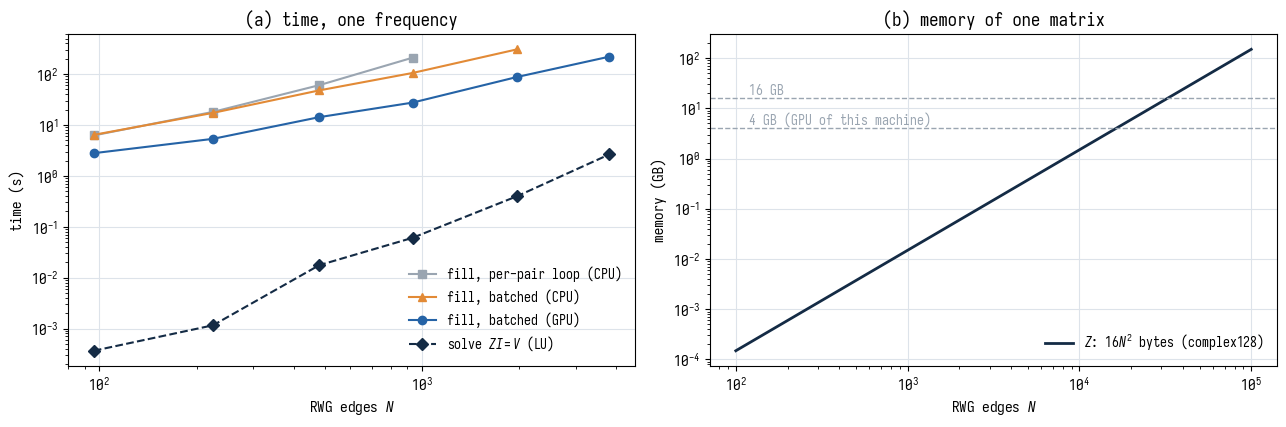

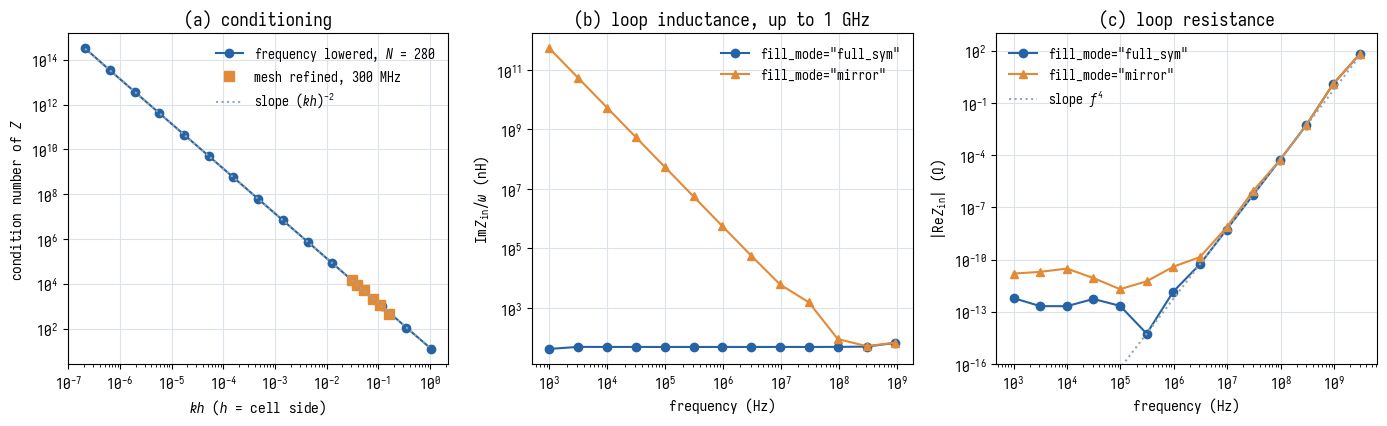

In [7]:
# Figure 1: cost
fig, (ax_t, ax_m) = plt.subplots(1, 2, figsize=(13, 4.4))
Ns = np.array([r["N"] for r in cost])
for key, color, marker, label in (("t_loop_cpu", GREY, "s", "fill, per-pair loop (CPU)"),
                                  ("t_batched_cpu", AMBER, "^", "fill, batched (CPU)"),
                                  ("t_gpu", BLUE, "o", "fill, batched (GPU)")):
    t = np.array([r[key] for r in cost], dtype=float)
    ok = np.isfinite(t)
    ax_t.loglog(Ns[ok], t[ok], "-" + marker, color=color, label=label)
t_solve = np.array([r["t_solve"] for r in cost])
ax_t.loglog(Ns, t_solve, "--D", color=INK, label=r"solve $ZI = V$ (LU)")
ax_t.set_xlabel("RWG edges $N$")
ax_t.set_ylabel("time (s)")
ax_t.set_title("(a) time, one frequency")
ax_t.legend(frameon=False, fontsize=10, loc="lower right")

N_line = np.logspace(2, 5, 50)
ax_m.loglog(N_line, 16 * N_line ** 2 / 2 ** 30, color=INK, lw=2, label=r"$Z$: $16N^2$ bytes (complex128)")
for gb, txt in ((4, "4 GB (GPU of this machine)"), (16, "16 GB")):
    ax_m.axhline(gb, color=GREY, ls="--", lw=1)
    ax_m.text(1.2e2, gb * 1.15, txt, color=GREY, fontsize=10)
ax_m.set_xlabel("RWG edges $N$")
ax_m.set_ylabel("memory (GB)")
ax_m.set_title("(b) memory of one matrix")
ax_m.legend(frameon=False, fontsize=10, loc="lower right")
for ax in (ax_t, ax_m):
    ax.grid(True, which="major", color="#dde3ea", lw=0.8)
fig.tight_layout()
fig.savefig(OUT_DIR / "numerical_limits_cost.svg", bbox_inches="tight", facecolor="white")
plt.show()

# Figure 2: conditioning and the low-frequency loop
fig, (ax_c, ax_l, ax_r) = plt.subplots(1, 3, figsize=(14, 4.4))
kh_f = np.array([r["kh"] for r in cond_freq]); c_f = np.array([r["cond"] for r in cond_freq])
ax_c.loglog(kh_f, c_f, "-o", color=BLUE, label=f"frequency lowered, $N$ = {mesh_cond.n_edges}")
ax_c.loglog([r["kh"] for r in cond_mesh], [r["cond"] for r in cond_mesh], "s", color=AMBER, ms=7,
            label="mesh refined, 300 MHz")
i0 = len(kh_f) // 2
ax_c.loglog(kh_f, c_f[i0] * (kh_f / kh_f[i0]) ** -2, ":", color=GREY, label=r"slope $(kh)^{-2}$")
ax_c.set_xlabel(r"$kh$ ($h$ = cell side)")
ax_c.set_ylabel(r"condition number of $Z$")
ax_c.set_title("(a) conditioning")
ax_c.legend(frameon=False, fontsize=10, loc="upper right")

F_MAX_L = 1.0e9          # below the first resonance of the loop
for mode, color, marker in (("full_sym", BLUE, "o"), ("mirror", AMBER, "^")):
    rows = loop_rows[mode]
    f = np.array([r["f"] for r in rows])
    L = np.array([r["L_nH"] for r in rows])
    keep = f <= F_MAX_L
    ax_l.loglog(f[keep], L[keep], "-" + marker, color=color, label=f'fill_mode="{mode}"')
    ax_r.loglog(f, np.abs([r["R"] for r in rows]), "-" + marker, color=color, label=f'fill_mode="{mode}"')
f = np.array([r["f"] for r in loop_rows["full_sym"]]); R = np.array([r["R"] for r in loop_rows["full_sym"]])
j = len(f) - 4
ax_r.loglog(f, R[j] * (f / f[j]) ** 4, ":", color=GREY, label=r"slope $f^4$")
ax_r.set_ylim(1e-16, 1e3)
ax_l.set_xlabel("frequency (Hz)"); ax_l.set_ylabel(r"$\mathrm{Im}\,Z_\mathrm{in}/\omega$ (nH)")
ax_l.set_title("(b) loop inductance, up to 1 GHz")
ax_r.set_xlabel("frequency (Hz)"); ax_r.set_ylabel(r"$|\mathrm{Re}\,Z_\mathrm{in}|$ ($\Omega$)")
ax_r.set_title("(c) loop resistance")
for ax in (ax_l, ax_r):
    ax.legend(frameon=False, fontsize=10, loc="upper right" if ax is ax_l else "upper left")
for ax in (ax_c, ax_l, ax_r):
    ax.grid(True, which="major", color="#dde3ea", lw=0.8)
fig.tight_layout()
fig.savefig(OUT_DIR / "numerical_limits_conditioning.svg", bbox_inches="tight", facecolor="white")
plt.show()

In [8]:
def git_commit(repo=Path("../..")):
    """Current commit, read from .git directly (git may not be on the kernel's PATH)."""
    git_dir = repo / ".git"
    head = (git_dir / "HEAD").read_text().strip()
    if not head.startswith("ref: "):
        return head[:7]
    ref_file = git_dir / head[5:]
    if ref_file.exists():
        return ref_file.read_text().strip()[:7]
    for line in (git_dir / "packed-refs").read_text().splitlines():
        if line.endswith(" " + head[5:]):
            return line.split()[0][:7]
    return "unknown"

clean = lambda rows: [{k: (None if isinstance(v, float) and not np.isfinite(v) else v) for k, v in r.items()} for r in rows]
provenance = {
    "figures": ["numerical_limits_cost.svg", "numerical_limits_conditioning.svg"],
    "notebook": "documentation/figure_notebooks/theory_numerical_limits.ipynb",
    "solver_commit": git_commit(),
    "generated": datetime.date.today().isoformat(),
    "machine": machine,
    "cost": {"plate_side_m": SIDE_COST, "frequency_hz": F_COST, "budget_s": BUDGET_S, "rows": clean(cost),
             "profile_N": mesh_prof.n_edges, "profile_total_s": profile_total,
             "profile_own_time_top": [dict(function=n, module=m, seconds=t) for n, m, t in profile_tottime]},
    "conditioning": {"plate_side_m": SIDE_COND, "frequency_sweep_N": mesh_cond.n_edges, "h_m": h_cond,
                     "vs_frequency": cond_freq, "vs_mesh_at_300MHz": cond_mesh},
    "loop": {"side_centerline_m": 0.020, "width_m": 0.002, "N": loop.n_edges, "rows": loop_rows},
    "gmsh_reproducibility": gmsh_repro,
}
(OUT_DIR / "numerical_limits.json").write_text(json.dumps(provenance, indent=2), encoding="utf-8")
print("written", OUT_DIR / "numerical_limits.json")

written ..\source\figures\generated\numerical_limits.json
